<a href="https://colab.research.google.com/github/SobiaNoorAI/cxr-foundation-model-shift-robustness/blob/main/notebooks/03_corruption_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## setup

In [5]:
from google.colab import drive
drive.mount('/content/drive')
import os, io, numpy as np, pandas as pd, torch

BASE = "/content/drive/MyDrive/phd_projects/cxr_shift"
SEED = 42
!unzip -q -n {BASE}/data_512.zip -d /content

df = pd.read_csv(f"{BASE}/metadata.csv")
paths = df.path512.tolist()
assert all(os.path.exists(p) for p in paths), "some images are missing"
print(len(paths), "images ready | GPU:", torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
800 images ready | GPU: True


## train classifiers on clean features

In [6]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

ENC = ["resnet50_imagenet", "dinov2_base", "rad_dino"]
CLEAN = {k: np.load(f"{BASE}/features/{k}.npy") for k in ENC}
y, hosp = df.label.values, df.hospital.values

def make_model():
    return make_pipeline(StandardScaler(),
        LogisticRegressionCV(Cs=[0.001, 0.01, 0.1, 1, 10], cv=5,
                             scoring="roc_auc", max_iter=5000, random_state=SEED))

def boot_auc(y_true, scores, n=500, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    aucs = [roc_auc_score(y_true[i], scores[i]) for i in
            (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n))]
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    return roc_auc_score(y_true, scores), lo, hi

models = {}
for enc in ENC:
    for tr in ["shenzhen", "montgomery"]:
        m = hosp == tr
        models[(enc, tr)] = make_model().fit(CLEAN[enc][m], y[m])
print("trained", len(models), "models (clean images only)")

trained 6 models (clean images only)


## load the three encoders

In [7]:
import timm
from PIL import Image
from tqdm import tqdm
from transformers import AutoImageProcessor, AutoModel
device = "cuda"

class Enc:
    def __init__(self, name):
        self.name = name
        if name == "resnet50_imagenet":
            self.model = timm.create_model("resnet50", pretrained=True, num_classes=0).to(device).eval()
            self.tf = timm.data.create_transform(**timm.data.resolve_data_config({}, model=self.model))
        else:
            hf = {"dinov2_base": "facebook/dinov2-base", "rad_dino": "microsoft/rad-dino"}[name]
            self.proc = AutoImageProcessor.from_pretrained(hf)
            self.model = AutoModel.from_pretrained(hf).to(device).eval().half()
    @torch.no_grad()
    def __call__(self, imgs):
        if self.name == "resnet50_imagenet":
            x = torch.stack([self.tf(im) for im in imgs]).to(device)
            return self.model(x).cpu().numpy()
        x = self.proc(images=imgs, return_tensors="pt")["pixel_values"].to(device).half()
        return self.model(pixel_values=x).pooler_output.float().cpu().numpy()

encoders = {k: Enc(k) for k in ENC}

# Sanity check: re-extracting clean images should match the saved features
def cos(a, b): return (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))
imgs = [Image.open(p).convert("RGB") for p in paths[:16]]
for e in ENC:
    print(e, "min cosine vs saved:", cos(encoders[e](imgs), CLEAN[e][:16]).min().round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

resnet50_imagenet min cosine vs saved: 1.0
dinov2_base min cosine vs saved: 1.0
rad_dino min cosine vs saved: 1.0


## define the corruptions

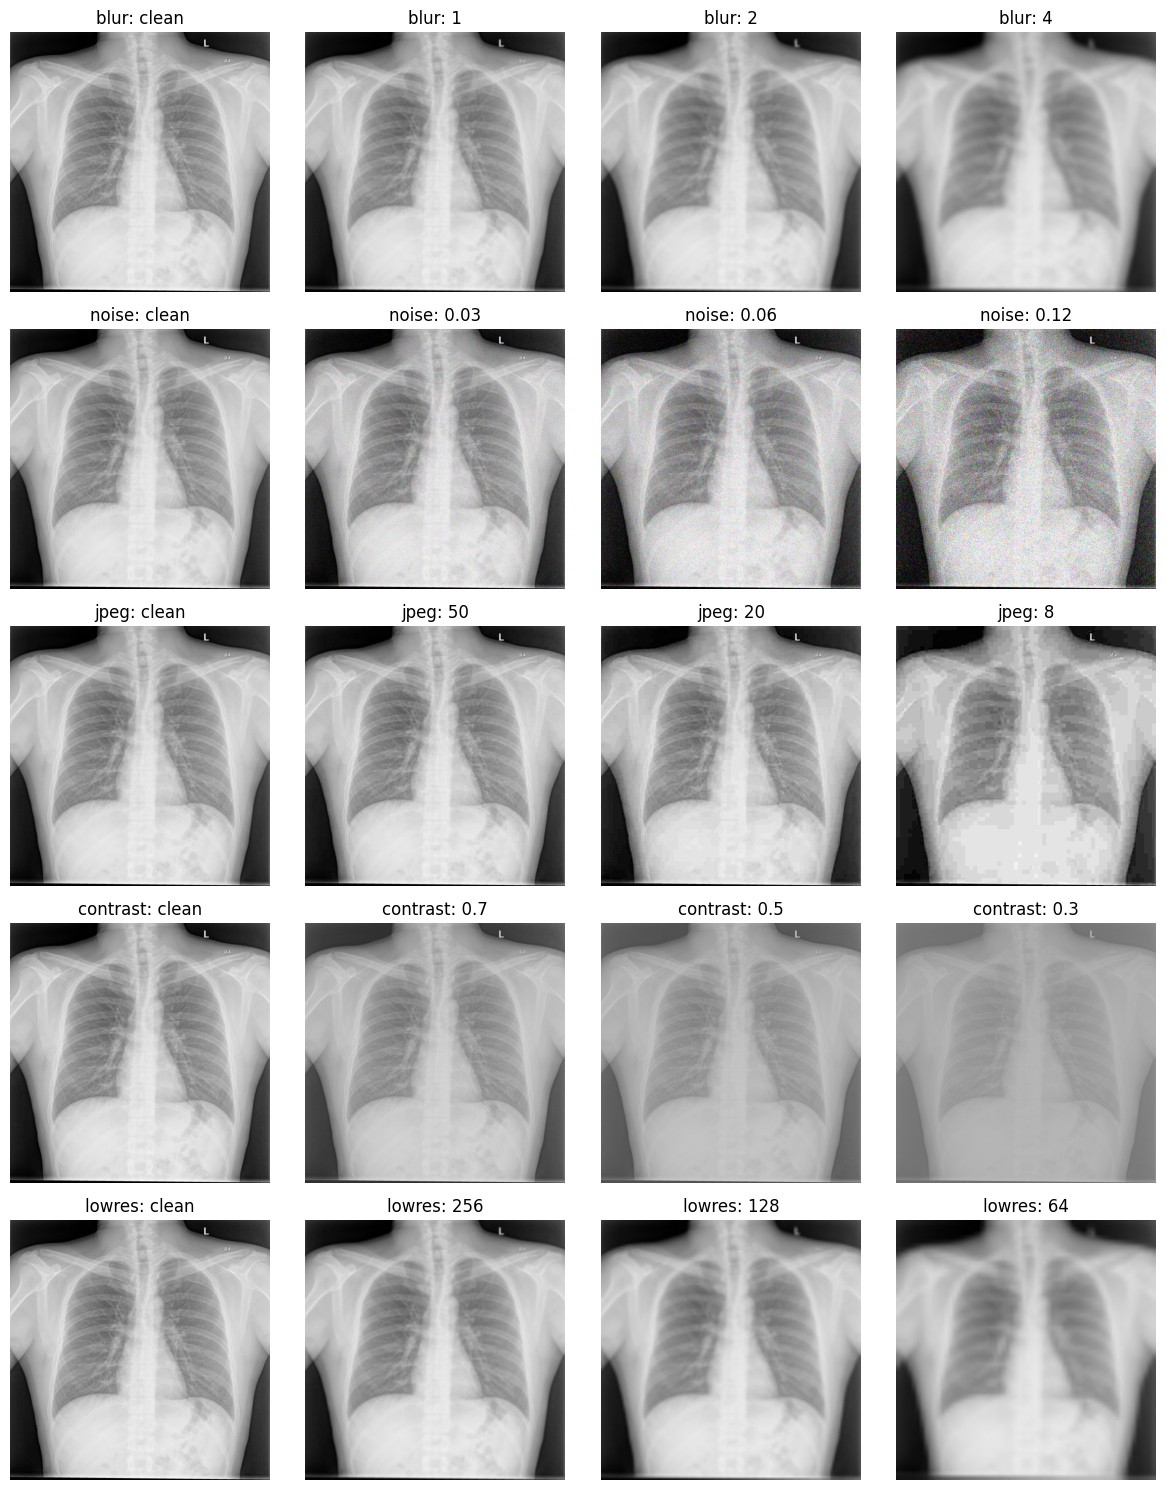

In [8]:
from PIL import ImageFilter, ImageEnhance
import matplotlib.pyplot as plt

def c_blur(img, idx, r): return img.filter(ImageFilter.GaussianBlur(r))
def c_noise(img, idx, s):
    rng = np.random.default_rng(SEED + idx)
    a = np.asarray(img).astype(np.float32) / 255
    a = np.clip(a + rng.normal(0, s, a.shape), 0, 1)
    return Image.fromarray((a * 255).astype(np.uint8))
def c_jpeg(img, idx, q):
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=q); buf.seek(0)
    return Image.open(buf).convert("RGB")
def c_contrast(img, idx, f): return ImageEnhance.Contrast(img).enhance(f)
def c_lowres(img, idx, s):
    return img.resize((s, s), Image.BILINEAR).resize((512, 512), Image.BILINEAR)

CORR = {   # name: (function, [severity 1, 2, 3])
    "blur":     (c_blur,     [1, 2, 4]),
    "noise":    (c_noise,    [0.03, 0.06, 0.12]),
    "jpeg":     (c_jpeg,     [50, 20, 8]),
    "contrast": (c_contrast, [0.7, 0.5, 0.3]),
    "lowres":   (c_lowres,   [256, 128, 64]),
}

base = Image.open(paths[0]).convert("RGB")
fig, axes = plt.subplots(5, 4, figsize=(12, 15))
for r, (cname, (fn, levels)) in enumerate(CORR.items()):
    axes[r, 0].imshow(base); axes[r, 0].set_title(f"{cname}: clean")
    for c, lv in enumerate(levels, start=1):
        axes[r, c].imshow(fn(base, 0, lv)); axes[r, c].set_title(f"{cname}: {lv}")
for a in axes.ravel(): a.axis("off")
plt.tight_layout()
os.makedirs(f"{BASE}/results", exist_ok=True)
plt.savefig(f"{BASE}/results/03_corruption_examples.png", dpi=150)
plt.show()

## extract features for every corruption

In [9]:
os.makedirs(f"{BASE}/features_corrupt", exist_ok=True)
BS = 16
for cname, (fn, levels) in CORR.items():
    for lv in levels:
        out = f"{BASE}/features_corrupt/{cname}_{lv}.npz"
        if os.path.exists(out):
            continue                                   # resume after a disconnect
        feats = {e: [] for e in ENC}
        for i in tqdm(range(0, len(paths), BS), desc=f"{cname} {lv}"):
            imgs = [fn(Image.open(p).convert("RGB"), i + j, lv)
                    for j, p in enumerate(paths[i:i + BS])]
            for e in ENC:
                feats[e].append(encoders[e](imgs))
        np.savez(out, **{e: np.concatenate(v) for e, v in feats.items()})
print("done")

done


## evaluate and save the table

In [10]:
rows = []
DIRS = [("shenzhen", "montgomery"), ("montgomery", "shenzhen")]

def add(cname, sev, lv, enc, tr, te, X):
    mte = hosp == te
    s = models[(enc, tr)].predict_proba(X[mte])[:, 1]
    auc, lo, hi = boot_auc(y[mte], s)
    rows.append(dict(corruption=cname, severity=sev, level=lv, encoder=enc,
                     direction=f"{tr} → {te}", AUROC=auc, CI_low=lo, CI_high=hi))

for enc in ENC:
    for tr, te in DIRS:
        add("clean", 0, 0, enc, tr, te, CLEAN[enc])
for cname, (fn, levels) in CORR.items():
    for sev, lv in enumerate(levels, start=1):
        Z = np.load(f"{BASE}/features_corrupt/{cname}_{lv}.npz")
        for enc in ENC:
            for tr, te in DIRS:
                add(cname, sev, lv, enc, tr, te, Z[enc])

res = pd.DataFrame(rows)
res.round(4).to_csv(f"{BASE}/results/03_corruption_results.csv", index=False)
res[res.severity.isin([0, 3])].round(3)

,corruption,severity,level,encoder,direction,AUROC,CI_low,CI_high
0,clean,0,0.00,resnet50_imagenet,shenzhen → montgomery,0.557,0.451,0.650
1,clean,0,0.00,resnet50_imagenet,montgomery → shenzhen,0.675,0.639,0.717
2,clean,0,0.00,dinov2_base,shenzhen → montgomery,0.836,0.765,0.898
3,clean,0,0.00,dinov2_base,montgomery → shenzhen,0.746,0.710,0.782
4,clean,0,0.00,rad_dino,shenzhen → montgomery,0.970,0.944,0.989
5,clean,0,0.00,rad_dino,montgomery → shenzhen,0.938,0.919,0.956
18,blur,3,4.00,resnet50_imagenet,shenzhen → montgomery,0.415,0.311,0.528
19,blur,3,4.00,resnet50_imagenet,montgomery → shenzhen,0.621,0.581,0.666
20,blur,3,4.00,dinov2_base,shenzhen → montgomery,0.769,0.689,0.849
21,blur,3,4.00,dinov2_base,montgomery → shenzhen,0.744,0.711,0.781


## plot

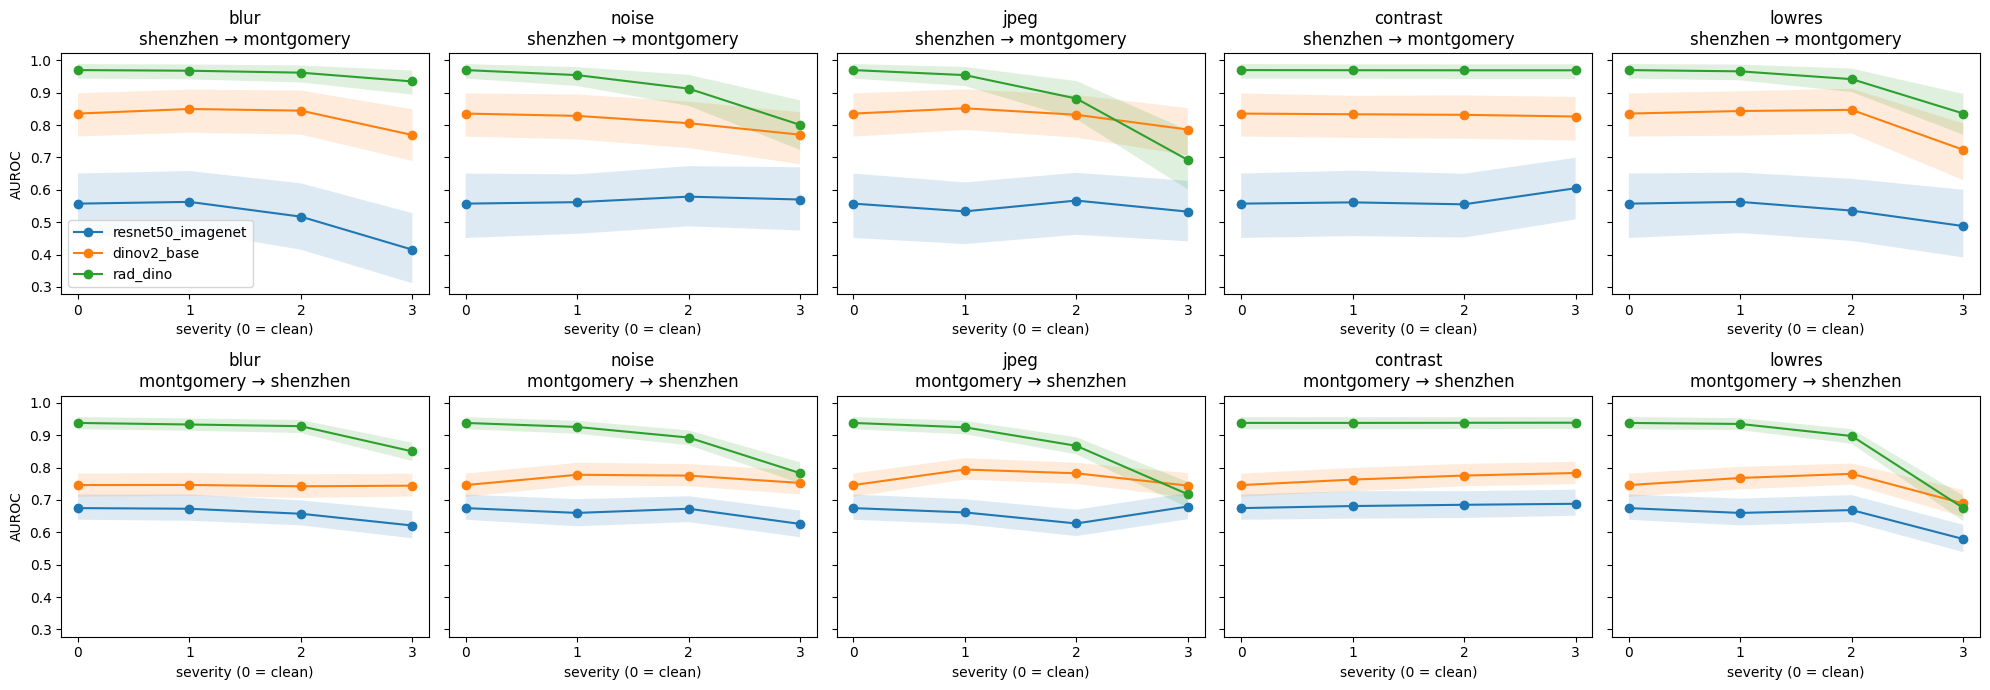

In [12]:
dirs = res.direction.unique()
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True)
for r, d in enumerate(dirs):
    for c, cname in enumerate(CORR):
        ax = axes[r, c]
        for enc in ENC:
            q = lambda df_, n: df_[(df_.corruption == n) & (df_.encoder == enc) & (df_.direction == d)]
            sub = pd.concat([q(res, "clean"), q(res, cname)]).sort_values("severity")
            ax.plot(sub.severity, sub.AUROC, marker="o", label=enc)
            ax.fill_between(sub.severity, sub.CI_low, sub.CI_high, alpha=0.15)
        ax.set_title(f"{cname}\n{d}")
        ax.set_xticks([0, 1, 2, 3]); ax.set_xlabel("severity (0 = clean)")
axes[0, 0].set_ylabel("AUROC"); axes[1, 0].set_ylabel("AUROC")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(f"{BASE}/results/03_corruption_curves.png", dpi=200)
plt.show()

In [13]:
Z = np.load(f"{BASE}/features_corrupt/contrast_0.3.npz")
for e in ENC:
    print(e, "mean cosine, clean vs contrast-0.3:", cos(Z[e], CLEAN[e]).mean().round(4))

resnet50_imagenet mean cosine, clean vs contrast-0.3: 0.9317
dinov2_base mean cosine, clean vs contrast-0.3: 0.9921
rad_dino mean cosine, clean vs contrast-0.3: 0.9869
